# Étape 1 — Exploration des données images (Personne 1 : Vision)
Projet : détection des maladies des plantes + assistant textuel (RAG)

Datasets : **PlantVillage** (images de laboratoire, ~54k, 38 classes) et **PlantDoc** (images de terrain, ~2,6k, 27 classes).

Contenu : 1) chargement, 2) distribution des classes, 3) grille d'exemples, 4) dimensions et formats, 5) images corrompues et doublons, 6) correspondance des classes PlantVillage / PlantDoc, 7) synthèse.

In [1]:
!git clone --depth 1 https://github.com/spMohanty/PlantVillage-Dataset.git
!git clone --depth 1 https://github.com/pratikkayal/PlantDoc-Dataset.git
!ls PlantVillage-Dataset/raw/color | head
!ls PlantDoc-Dataset

Cloning into 'PlantVillage-Dataset'...
remote: Enumerating objects: 163219, done.
remote: Counting objects: 100% (163219/163219), done.
remote: Compressing objects: 100% (163125/163125), done.
remote: Total 163219 (delta 93), reused 163215 (delta 93), pack-reused 0 (from 0)
Receiving objects: 100% (163219/163219), 2.00 GiB | 25.68 MiB/s, done.
Resolving deltas: 100% (93/93), done.
Updating files: 100% (182404/182404), done.
Cloning into 'PlantDoc-Dataset'...
remote: Enumerating objects: 2628, done.
remote: Counting objects: 100% (2628/2628), done.
remote: Compressing objects: 100% (2627/2627), done.
remote: Total 2628 (delta 1), reused 2616 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (2628/2628), 932.91 MiB | 29.83 MiB/s, done.
Resolving deltas: 100% (1/1), done.
Updating files: 100% (2581/2581), done.
Apple___Apple_scab
Apple___Black_rot
Apple___Cedar_apple_rust
Apple___healthy
Blueberry___healthy
Cherry_(including_sour)___healthy
Cherry_(including_sour)___Powdery_mildew

In [2]:
!pip install -q imagehash
!ls PlantDoc-Dataset/train | head -5
!ls PlantDoc-Dataset/test | head -5

Apple leaf
Apple rust leaf
Apple Scab Leaf
Bell_pepper leaf
Bell_pepper leaf spot
Apple leaf
Apple rust leaf
Apple Scab Leaf
Bell_pepper leaf
Bell_pepper leaf spot


In [3]:
# !pip install pandas matplotlib pillow imagehash tqdm
import os, hashlib, random
from pathlib import Path
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm import tqdm

random.seed(42)

# A ADAPTER : dossiers où vous avez téléchargé les datasets (un sous-dossier par classe)
PV_DIR = Path("PlantVillage-Dataset/raw/color")
PD_TRAIN = Path("PlantDoc-Dataset/train")
PD_TEST = Path("PlantDoc-Dataset/test")
EXTS = {".jpg", ".jpeg", ".png", ".JPG", ".JPEG", ".PNG"}

## 1. Chargement : une ligne par image

In [4]:
def index_dataset(root, name):
    rows = []
    for cls_dir in sorted(p for p in Path(root).iterdir() if p.is_dir()):
        for f in cls_dir.iterdir():
            if f.suffix in EXTS:
                rows.append({"dataset": name, "classe": cls_dir.name, "chemin": str(f)})
    return pd.DataFrame(rows)

df_pv = index_dataset(PV_DIR, "PlantVillage")
df_pd = pd.concat([index_dataset(PD_TRAIN, "PlantDoc-train"),
                   index_dataset(PD_TEST, "PlantDoc-test")], ignore_index=True)
df = pd.concat([df_pv, df_pd], ignore_index=True)

print(df.groupby("dataset").agg(images=("chemin", "count"), classes=("classe", "nunique")))
df.head()

                images  classes
dataset                        
PlantDoc-test      236       27
PlantDoc-train    2342       28
PlantVillage     54305       38


,dataset,classe,chemin
0,PlantVillage,Apple___Apple_scab,PlantVillage-Dataset/raw/color/Apple___Apple_s...
1,PlantVillage,Apple___Apple_scab,PlantVillage-Dataset/raw/color/Apple___Apple_s...
2,PlantVillage,Apple___Apple_scab,PlantVillage-Dataset/raw/color/Apple___Apple_s...
3,PlantVillage,Apple___Apple_scab,PlantVillage-Dataset/raw/color/Apple___Apple_s...
4,PlantVillage,Apple___Apple_scab,PlantVillage-Dataset/raw/color/Apple___Apple_s...


## 2. Distribution des classes (visualisation 1)

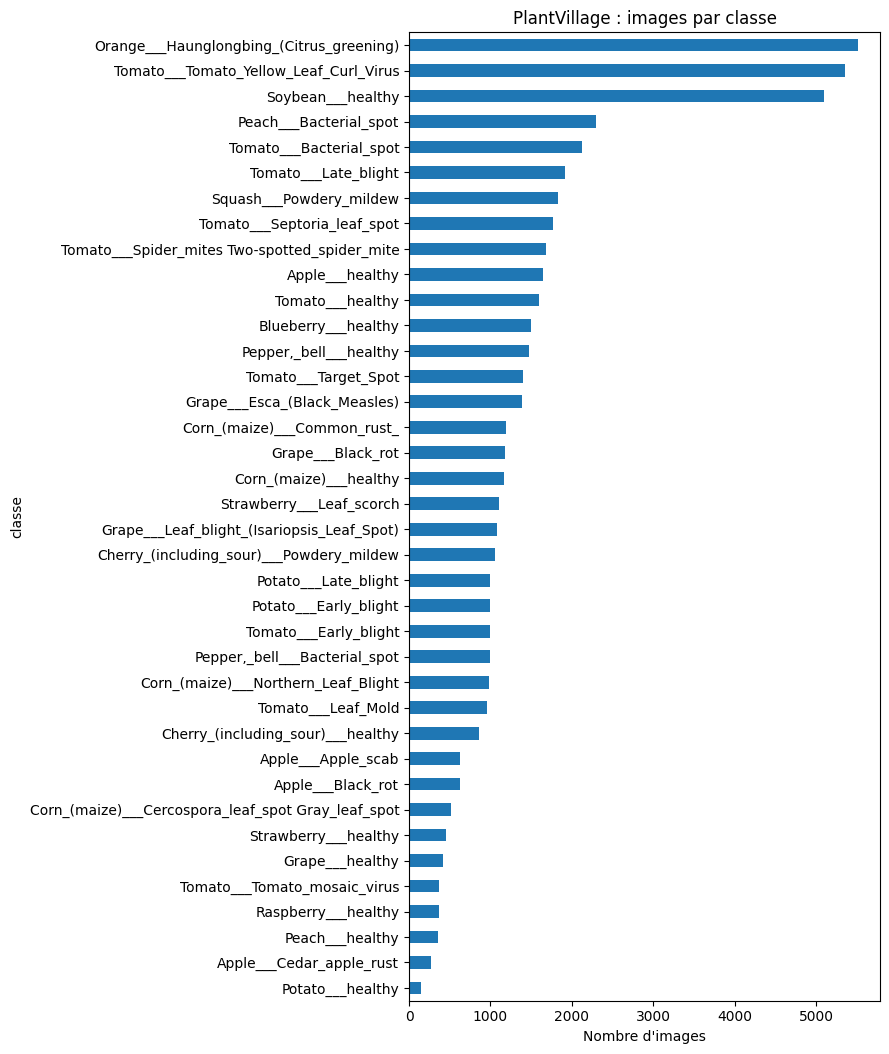

Min : 152 | Max : 5507 | Ratio déséquilibre max/min : 36.2


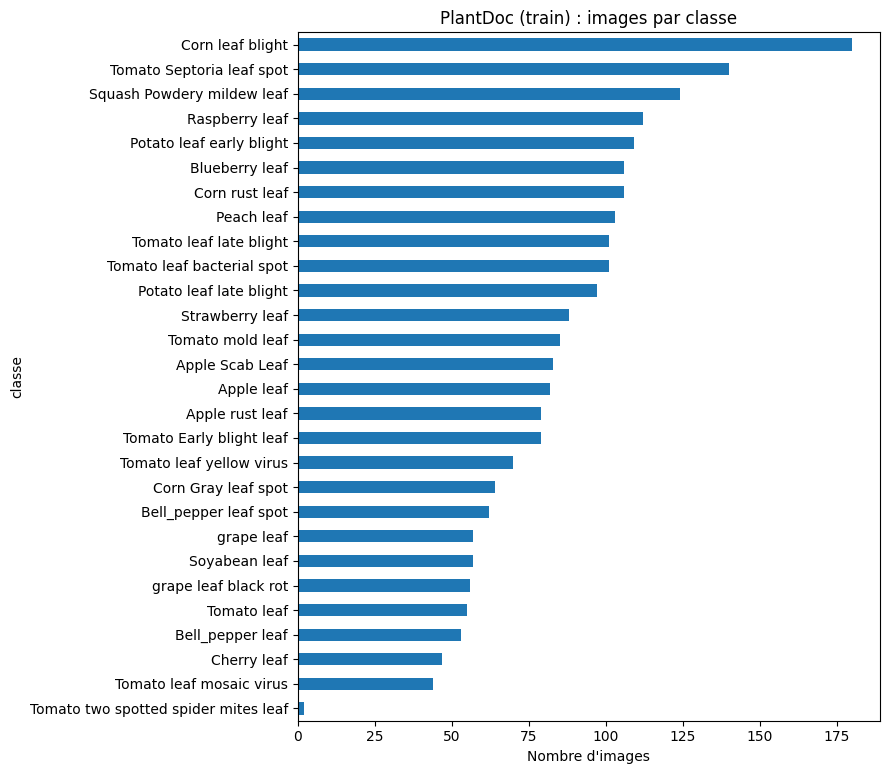

Min : 2 | Max : 180 | Ratio déséquilibre max/min : 90.0


In [5]:
def plot_class_distribution(d, title):
    counts = d["classe"].value_counts().sort_values()
    fig, ax = plt.subplots(figsize=(9, max(4, 0.28 * len(counts))))
    counts.plot.barh(ax=ax)
    ax.set_title(title); ax.set_xlabel("Nombre d'images")
    plt.tight_layout(); plt.show()
    print(f"Min : {counts.min()} | Max : {counts.max()} | Ratio déséquilibre max/min : {counts.max()/counts.min():.1f}")

plot_class_distribution(df_pv, "PlantVillage : images par classe")
plot_class_distribution(df_pd[df_pd.dataset == "PlantDoc-train"], "PlantDoc (train) : images par classe")

## 3. Grille d'exemples : laboratoire vs terrain (visualisation 2)

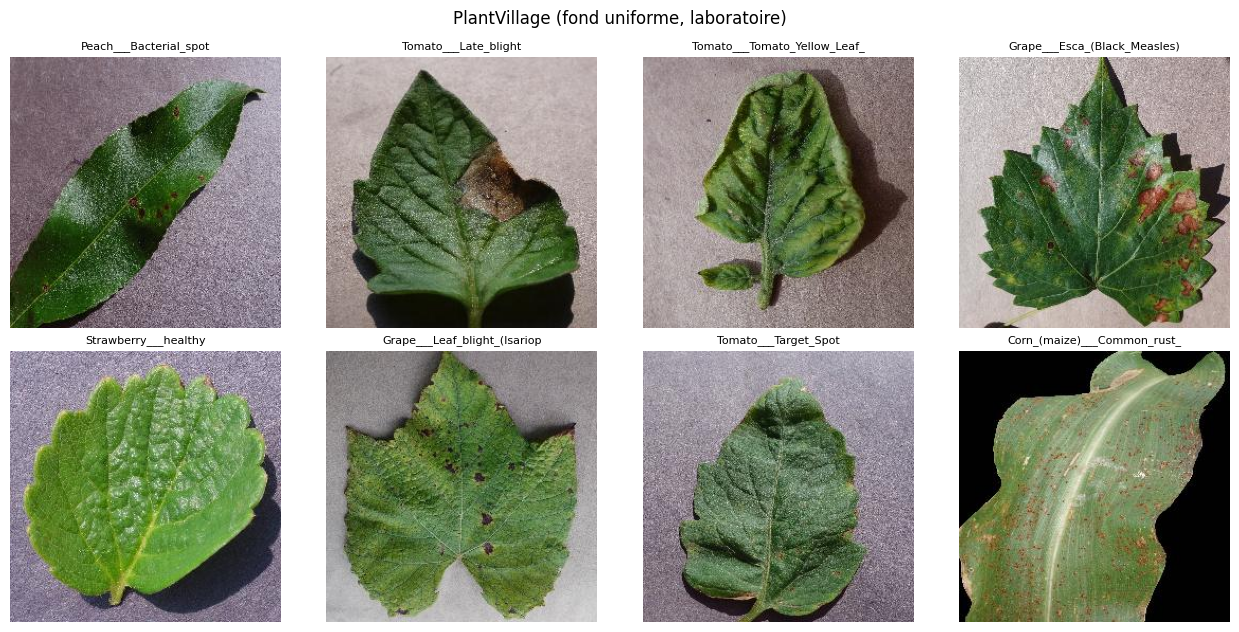

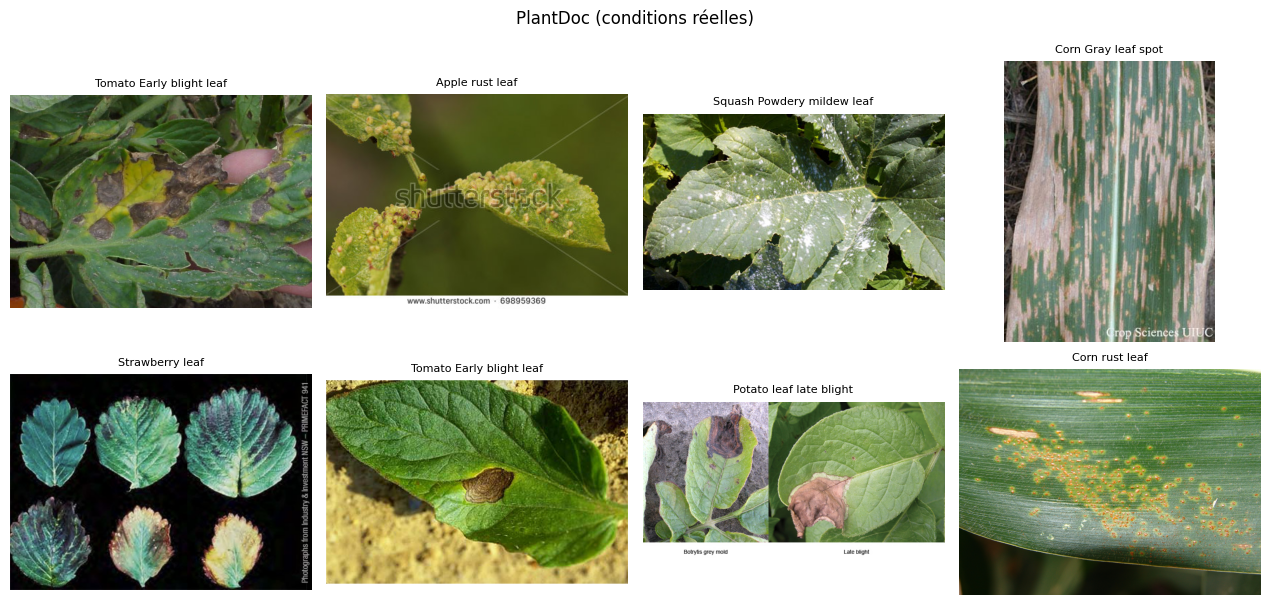

In [6]:
def sample_grid(d, n=8, title=""):
    sample = d.sample(n, random_state=1)
    cols = 4; rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(3.2 * cols, 3.2 * rows))
    for ax, (_, r) in zip(axes.ravel(), sample.iterrows()):
        ax.imshow(Image.open(r["chemin"]).convert("RGB"))
        ax.set_title(r["classe"][:28], fontsize=8); ax.axis("off")
    for ax in axes.ravel()[n:]: ax.axis("off")
    fig.suptitle(title); plt.tight_layout(); plt.show()

sample_grid(df_pv, 8, "PlantVillage (fond uniforme, laboratoire)")
sample_grid(df_pd, 8, "PlantDoc (conditions réelles)")

PlantDoc présente des fonds hétérogènes, des filigranes, des montages multi-feuilles et un bruit d’annotation, ce qui le rend plus réaliste mais plus difficile que PlantVillage. » C’est ce qui justifie votre test de généralisation PlantVillage vers PlantDoc

## 4. Dimensions, formats et modes couleur

100%|██████████| 2000/2000 [00:00<00:00, 2312.74it/s]


PlantVillage
       largeur  hauteur
count   2000.0   2000.0
mean     256.0    256.0
std        0.0      0.0
min      256.0    256.0
25%      256.0    256.0
50%      256.0    256.0
75%      256.0    256.0
max      256.0    256.0
{'RGB': 2000} {'JPEG': 2000} 

PlantDoc
       largeur  hauteur
count   2000.0   2000.0
mean    1073.0    914.0
std      873.0    754.0
min      115.0     69.0
25%      500.0    400.0
50%      800.0    674.0
75%     1300.0   1192.0
max     6000.0   5312.0
{'RGB': 1991, 'CMYK': 5, 'RGBA': 3, 'L': 1} {'JPEG': 1996, 'PNG': 3, 'MPO': 1} 



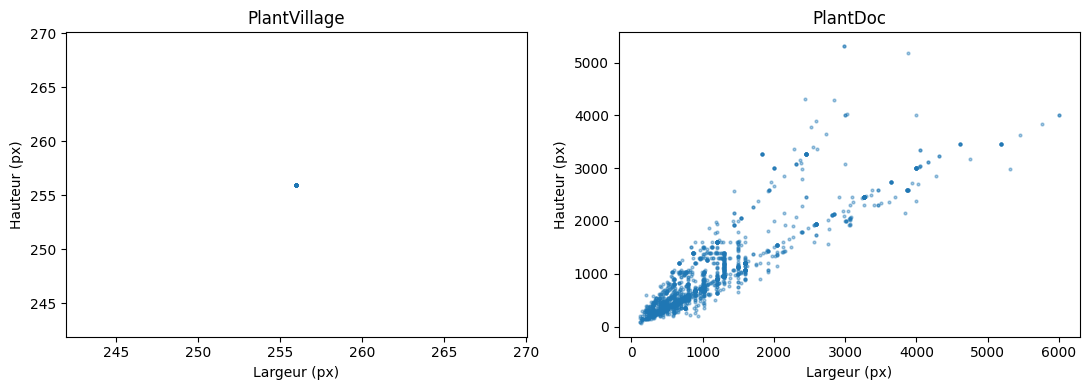

In [7]:
def image_stats(d, max_n=2000):
    d = d.sample(min(max_n, len(d)), random_state=0)
    out = []
    for p in tqdm(d["chemin"]):
        try:
            with Image.open(p) as im:
                out.append({"chemin": p, "largeur": im.width, "hauteur": im.height,
                            "mode": im.mode, "format": im.format})
        except Exception as e:
            out.append({"chemin": p, "erreur": str(e)})
    return pd.DataFrame(out)

stats_pv = image_stats(df_pv); stats_pd = image_stats(df_pd)
for name, s in [("PlantVillage", stats_pv), ("PlantDoc", stats_pd)]:
    print(name); print(s[["largeur", "hauteur"]].describe().round(0))
    print(s["mode"].value_counts().to_dict(), s["format"].value_counts().to_dict(), "\n")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(stats_pv.largeur, stats_pv.hauteur, s=4, alpha=.4); axes[0].set_title("PlantVillage")
axes[1].scatter(stats_pd.largeur, stats_pd.hauteur, s=4, alpha=.4); axes[1].set_title("PlantDoc")
for a in axes: a.set_xlabel("Largeur (px)"); a.set_ylabel("Hauteur (px)")
plt.tight_layout(); plt.show()

PlantVillage : les 2 000 images mesurent exactement 256 x 256 px, toutes en RGB et JPEG. D’où un seul point sur le graphique : dataset parfaitement uniforme.

PlantDoc : tailles très variables, de 115 x 69 px jusqu’à 6000 x 5312 px, avec une médiane d’environ 800 x 674 px. Le nuage étalé le montre bien.

Il y a aussi quelques cas particuliers dans PlantDoc :

5 images en CMYK, 3 en RGBA (avec transparence) et 1 en niveaux de gris (L).
Quelques fichiers PNG et un MPO, à côté des JPEG.

## 5. Images corrompues et doublons
- **Doublons exacts** : hash MD5 du fichier.
- **Quasi-doublons** : hash perceptuel (`imagehash`). Dans PlantVillage, la même feuille est souvent photographiée plusieurs fois, d'où un risque de **fuite de données** (data leakage) si le découpage train/test est aléatoire.

In [8]:
def md5(p):
    h = hashlib.md5()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""): h.update(chunk)
    return h.hexdigest()

df["md5"] = [md5(p) for p in tqdm(df["chemin"])]
dups = df[df.duplicated("md5", keep=False)].sort_values("md5")
print("Doublons exacts :", len(dups), "fichiers dans", dups["md5"].nunique(), "groupes")
print(dups.groupby("dataset").size())

# Doublons entre PlantDoc train et test (fuite possible)
tr = set(df[df.dataset == "PlantDoc-train"].md5); te = set(df[df.dataset == "PlantDoc-test"].md5)
print("Images communes PlantDoc train/test :", len(tr & te))

100%|██████████| 56883/56883 [00:33<00:00, 1679.56it/s]


Doublons exacts : 66 fichiers dans 33 groupes
dataset
PlantDoc-test     11
PlantDoc-train    13
PlantVillage      42
dtype: int64
Images communes PlantDoc train/test : 11


11 images du test PlantDoc sont des doublons exacts d’images du train (fuite de données). Elles seront retirées du test avant l’évaluation

In [9]:
import imagehash
def phash(p):
    try:
        with Image.open(p) as im: return str(imagehash.phash(im.convert("RGB")))
    except Exception: return None

sub = df_pv.sample(min(5000, len(df_pv)), random_state=0).copy()
sub["phash"] = [phash(p) for p in tqdm(sub["chemin"])]
near = sub[sub.duplicated("phash", keep=False) & sub.phash.notna()]
print("Quasi-doublons (phash identique) dans l'échantillon PlantVillage :", len(near))

100%|██████████| 5000/5000 [00:12<00:00, 414.06it/s]

Quasi-doublons (phash identique) dans l'échantillon PlantVillage : 2


In [12]:
mauvaises = []
for p in tqdm(df["chemin"]):
    try:
        with Image.open(p) as im:
            im.verify()
    except Exception:
        mauvaises.append(p)

print("Images corrompues :", len(mauvaises))

100%|██████████| 56883/56883 [00:28<00:00, 1973.77it/s]

Images corrompues : 0


## 6. Correspondance des classes PlantVillage / PlantDoc (base du test de généralisation)

In [10]:
import re
def norm(s):
    s = s.lower().replace("___", " ").replace("_", " ")
    return re.sub(r"[^a-z ]", " ", s).split()

pv_classes = sorted(df_pv.classe.unique()); pd_classes = sorted(df_pd.classe.unique())
print("PlantVillage :", pv_classes[:5], "...")
print("PlantDoc     :", pd_classes[:5], "...")

# Mapping automatique approximatif : plus grand recouvrement de mots. A VERIFIER MANUELLEMENT.
mapping = {}
for c in pd_classes:
    wc = set(norm(c))
    best = max(pv_classes, key=lambda p: len(wc & set(norm(p))))
    score = len(wc & set(norm(best)))
    mapping[c] = best if score >= 2 else None
pd.Series(mapping, name="classe PlantVillage proche").to_frame()

PlantVillage : ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy'] ...
PlantDoc     : ['Apple Scab Leaf', 'Apple leaf', 'Apple rust leaf', 'Bell_pepper leaf', 'Bell_pepper leaf spot'] ...


,classe PlantVillage proche
Apple Scab Leaf,Apple___Apple_scab
Apple leaf,None
Apple rust leaf,Apple___Cedar_apple_rust
Bell_pepper leaf,"Pepper,_bell___Bacterial_spot"
Bell_pepper leaf spot,"Pepper,_bell___Bacterial_spot"
Blueberry leaf,None
Cherry leaf,None
Corn Gray leaf spot,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...
Corn leaf blight,Corn_(maize)___Northern_Leaf_Blight
Corn rust leaf,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...


In [11]:
mapping_final = {
    "Apple Scab Leaf": "Apple___Apple_scab",
    "Apple leaf": "Apple___healthy",
    "Apple rust leaf": "Apple___Cedar_apple_rust",
    "Bell_pepper leaf": "Pepper,_bell___healthy",
    "Bell_pepper leaf spot": "Pepper,_bell___Bacterial_spot",
    "Blueberry leaf": "Blueberry___healthy",
    "Cherry leaf": "Cherry_(including_sour)___healthy",
    "Corn Gray leaf spot": "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot",
    "Corn leaf blight": "Corn_(maize)___Northern_Leaf_Blight",
    "Corn rust leaf": "Corn_(maize)___Common_rust_",
    "Peach leaf": "Peach___healthy",
    "Potato leaf early blight": "Potato___Early_blight",
    "Potato leaf late blight": "Potato___Late_blight",
    "Raspberry leaf": "Raspberry___healthy",
    "Soyabean leaf": "Soybean___healthy",
    "Squash Powdery mildew leaf": "Squash___Powdery_mildew",
    "Strawberry leaf": "Strawberry___healthy",
    "Tomato Early blight leaf": "Tomato___Early_blight",
    "Tomato Septoria leaf spot": "Tomato___Septoria_leaf_spot",
    "Tomato leaf": "Tomato___healthy",
    "Tomato leaf bacterial spot": "Tomato___Bacterial_spot",
    "Tomato leaf late blight": "Tomato___Late_blight",
    "Tomato leaf mosaic virus": "Tomato___Tomato_mosaic_virus",
    "Tomato leaf yellow virus": "Tomato___Tomato_Yellow_Leaf_Curl_Virus",
    "Tomato mold leaf": "Tomato___Leaf_Mold",
    "Tomato two spotted spider mites leaf": None,   # 2 images : exclue
    "grape leaf": "Grape___healthy",
    "grape leaf black rot": "Grape___Black_rot",
}

# Vérification : chaque classe PlantVillage citée existe bien
inconnues = [v for v in mapping_final.values() if v and v not in pv_classes]
print("Classes PlantVillage introuvables :", inconnues)

df_pd["classe_pv"] = df_pd["classe"].map(mapping_final)
print(df_pd.groupby("dataset")["classe_pv"].apply(lambda s: s.notna().sum()))
print("Classes PlantVillage couvertes :", df_pd["classe_pv"].nunique(), "sur", len(pv_classes))

Classes PlantVillage introuvables : []
dataset
PlantDoc-test      236
PlantDoc-train    2340
Name: classe_pv, dtype: int64
Classes PlantVillage couvertes : 27 sur 38


## 7. Synthèse

**Nombre d'images et de classes**
- PlantVillage : 54 305 images et 38 classes. Le déséquilibre est grand : la plus grande classe a 5 507 images, la plus petite a 152 images (ratio 36,2).
- PlantDoc : 2 342 images pour l'entraînement (28 classes) et 236 images pour le test (27 classes). Une classe (Tomato two spotted spider mites) a seulement 2 images. On l'enlève. Les autres classes ont entre 44 et 180 images.

**Taille et format des images**
- PlantVillage : toutes les images ont la même taille (256 x 256 pixels). Elles sont en RGB et en JPEG.
- PlantDoc : les tailles sont très différentes (de 115 x 69 à 6000 x 5312 pixels). Quelques images ne sont pas en RGB. Il faut donc les convertir en RGB et les mettre à la même taille.

**Doublons**
- Doublons exacts : 42 fichiers dans PlantVillage et 24 dans PlantDoc.
- 11 images du test de PlantDoc sont aussi dans l'entraînement. C'est un problème, car le modèle les a déjà vues. On va les enlever du test.
- Images presque identiques : 2 dans un échantillon de 5 000 images de PlantVillage. Il y en a sûrement plus en réalité.

**Qualité des données**
- PlantVillage : les photos sont prises en laboratoire, avec un fond simple.
- PlantDoc : les photos sont prises dans la nature, avec des fonds très différents. Il y a aussi des logos (shutterstock), des photos avec plusieurs feuilles, des erreurs d'étiquettes et peu d'images par classe.

**Classes communes**
- 27 classes de PlantVillage existent aussi dans PlantDoc. Nous avons vérifié la correspondance à la main.
- 11 classes de PlantVillage n'existent pas dans PlantDoc. On ne peut pas les tester sur des photos de terrain.

**Ce qu'on va faire à l'Étape 2**
- Préparer les images : conversion en RGB, même taille (par exemple 224 x 224), normalisation.
- Séparer les données avec soin pour éviter les doublons entre entraînement et test.
- Ajouter des variations aux images (fond, lumière, rotation) et donner plus de poids aux petites classes.
- Entraîner le modèle sur PlantVillage et le tester sur PlantDoc (27 classes communes).
